# LSTM 实验与结果分析

COMP9444 · 人群中的行人轨迹预测

这份 Notebook 根据你上传的 8 次正式训练记录生成，包含模型说明、调参比较、三次重复实验、统计和图表。运行分析代码只读取已保存的 JSON，不会重新训练。

**最终配置：单层 LSTM，隐藏维度 64，初始学习率 0.001，在最终评分前根据验证结果选定。**第 4–6 节展示验证结果；第 8 节展示已完成的三种子测试：**ADE 21.5538 ± 0.0877 像素，FDE 37.2398 ± 0.1951 像素**（均值 ± 样本标准差）。

这是你负责的 LSTM 分析部分，可供小组整合进最终 Notebook；它不是五人整个项目的最终提交文件。

## 1. 实验记录与数据协议

共 8 次正式训练：单层基线和两层无层间 dropout 各跑种子 42、43、44；另外，较小学习率和两层 dropout 0.1 各跑种子 42。

每次训练使用同一份 GC 数据、时间划分和样本窗口。没有小样本限制。下面检查原始 JSON 中的指纹、配置、每轮样本数和最佳轮次，不重新生成原始数据，也不独立重跑训练。

In [1]:
%matplotlib inline
from pathlib import Path
import ast
import hashlib
import json
import math
import statistics

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Code, Markdown, display

# Find the experiment folder from common notebook working directories.
candidates = [
    Path.cwd(),
    Path.cwd() / "experiments" / "lstm",
    Path.cwd().parent / "experiments" / "lstm",
]
ROOT = next(
    (p.resolve() for p in candidates
     if (p / "baseline_seed42" / "result.json").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook with the experiments/lstm results.")

NAMES = (
    "baseline_seed42", "baseline_seed43", "baseline_seed44",
    "lr0005_seed42",
    "layers2_nodrop_seed42", "layers2_nodrop_seed43",
    "layers2_nodrop_seed44", "layers2_drop01_seed42",
)
runs = {
    name: json.loads((ROOT / name / "result.json").read_text())
    for name in NAMES
}
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#233044",
    "text.color": "#233044",
    "axes.edgecolor": "#A7B2C1",
    "grid.color": "#DCE3EB",
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})
COLORS = {
    "baseline": "#19766B",
    "layers2_nodrop": "#3D67B2",
    "lr0005": "#8A7C9E",
    "layers2_drop01": "#C37B25",
}

def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def score(run):
    m = run["validation"]
    return m["ade_px"] + 0.3 * (m["turn_ade_px"] or 0.0)

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / (name + ".svg"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Loaded", len(runs), "saved LSTM training runs.")

No event loop hook running.
Loaded 8 saved LSTM training runs.


In [2]:
# Check the recorded data protocol and checkpoint selection.
canonical = lambda value: json.dumps(value, sort_keys=True, separators=(",", ":"))
reference = runs["baseline_seed42"]
checks = {}
checks["eight_expected_runs"] = len(runs) == 8
checks["same_data_protocol"] = len({
    canonical(r["protocol"]["data"]) for r in runs.values()
}) == 1
checks["same_train_windows"] = len({
    r["protocol"]["train_subset_indices"] for r in runs.values()
}) == 1
checks["same_validation_windows"] = len({
    r["protocol"]["val_subset_indices"] for r in runs.values()
}) == 1
checks["all_full_training_and_validation"] = all(
    r["train_samples"] == 203475 and r["val_samples"] == 43814
    and r["protocol"]["train_limit"] is None
    and r["protocol"]["val_limit"] is None
    for r in runs.values()
)
checks["all_runs_cpu_torch_2_15"] = all(
    r["device"] == "cpu" and r["torch_version"] == "2.15.0"
    for r in runs.values()
)
checks["all_logs_report_test_not_evaluated"] = all(
    r["test_evaluated"] is False for r in runs.values()
)
checks["recorded_protocol_hashes_match"] = all(
    hashlib.sha256(canonical(r["protocol"]).encode()).hexdigest()
    == r["protocol_signature"] for r in runs.values()
)
checks["all_trace_lengths_match"] = all(
    len(r["trace"]) == r["epochs_completed"] == 16 for r in runs.values()
)
checks["every_epoch_visits_all_training_windows"] = all(
    row["seen"] == r["train_samples"]
    for r in runs.values() for row in r["trace"]
)
checks["best_epochs_match_recorded_selection_rule"] = all(
    min(r["trace"], key=lambda row: row["selection_objective"])["epoch"]
    == r["best_epoch"] for r in runs.values()
)
checks["saved_metrics_match_best_epoch"] = all(
    all(math.isclose(
        r["validation"][metric],
        r["trace"][r["best_epoch"] - 1]["validation"][metric],
        abs_tol=1e-6,
    ) for metric in ("ade_px", "fde_px", "turn_ade_px", "turn_fde_px"))
    for r in runs.values()
)
checks["seed_names_match_recorded_seeds"] = all(
    r["config"]["seed"] == int(name.rsplit("seed", 1)[1])
    for name, r in runs.items()
)
for variant in ("baseline", "layers2_nodrop"):
    configs = [
        {k: v for k, v in runs[f"{variant}_seed{s}"]["config"].items()
         if k != "seed"}
        for s in (42, 43, 44)
    ]
    checks[variant + "_repeats_change_only_seed"] = (
        len({canonical(c) for c in configs}) == 1
    )
def config_changes(left, right):
    return {
        k for k in left["config"]
        if left["config"][k] != right["config"][k]
    }
checks["learning_rate_screen_changes_only_learning_rate"] = (
    config_changes(runs["baseline_seed42"], runs["lr0005_seed42"])
    == {"learning_rate"}
)
checks["dropout_screen_changes_only_encoder_dropout"] = (
    config_changes(runs["layers2_nodrop_seed42"], runs["layers2_drop01_seed42"])
    == {"encoder_dropout"}
)
checks["lstm_parameter_counts_match_architecture"] = all(
    r["encoder_parameters"] == (
        4 * 64 * (4 + 64 + 2)
        + (r["config"]["recurrent_layers"] - 1) * 4 * 64 * (64 + 64 + 2)
    ) for r in runs.values()
)
checks["same_number_of_shared_parameters"] = len({
    r["parameters"] - r["encoder_parameters"] for r in runs.values()
}) == 1
for name in ("lstm_encoder.py", "motion_encoders.py"):
    ast.parse((ROOT.parents[1] / "gc_data_interface" / name).read_text())
checks["uploaded_python_sources_parse"] = True
if not all(checks.values()):
    raise ValueError({k: v for k, v in checks.items() if not v})
(ROOT / "analysis_audit.json").write_text(
    json.dumps(checks, indent=2) + "\n"
)
print(sum(checks.values()), "/", len(checks), "record checks passed.")
data = reference["protocol"]["data"]
show_table(
    ["Item", "Recorded setting"],
    [
        ["Training / validation / reserved test windows", "203,475 / 43,814 / 45,454"],
        ["History / prediction horizon", "5 observed points over 3.2 s / 6 future points over 4.8 s"],
        ["Observation interval", "0.8 seconds"],
        ["Validation turning windows", "8,045"],
        ["Hidden size / batch size / maximum epochs", "64 / 256 / 16"],
        ["Optimizer / initial learning rate", "AdamW / 0.001 (baseline)"],
        ["Minimum learning rate / weight decay", "0.0002 / 0.0001"],
        ["Model-selection rule", "Validation ADE + 0.3 × turning ADE"],
        ["Evaluation unit", "Pixels"],
        ["Data fingerprint", data["source_fingerprint"]],
    ],
)

20 / 20 record checks passed.


| Item | Recorded setting |
| --- | --- |
| Training / validation / reserved test windows | 203,475 / 43,814 / 45,454 |
| History / prediction horizon | 5 observed points over 3.2 s / 6 future points over 4.8 s |
| Observation interval | 0.8 seconds |
| Validation turning windows | 8,045 |
| Hidden size / batch size / maximum epochs | 64 / 256 / 16 |
| Optimizer / initial learning rate | AdamW / 0.001 (baseline) |
| Minimum learning rate / weight decay | 0.0002 / 0.0001 |
| Model-selection rule | Validation ADE + 0.3 × turning ADE |
| Evaluation unit | Pixels |
| Data fingerprint | 7c1c08e866d90054beae157c668c58992d8af2b436b619d7a0c61d1da0ddd0a0 |

## 2. LSTM 在整个模型里负责什么

LSTM 按时间顺序读取历史观测，逐步更新隐藏状态和细胞状态 [1, 4]。门结构控制哪些信息写入、保留和输出。代码调用 PyTorch 提供的 LSTM 层。

输入的 4 个特征是两个位置坐标和两个逐步位移。共享预处理会做行进方向对齐，并转成内部的 100 像素尺度。LSTM 输出每个时间点的特征和各层最后的隐藏状态；公共预测模块取最后一层的隐藏状态。

完整预测器还包含共享的位置特征分支、邻居注意力和中途点/终点解码器。原始输出是 [B, 1, 6, 2]，取唯一轨迹后是 [B, 6, 2]。你写的编码器本身并不直接输出未来 6 个点。

考虑周围行人的动机可以参考 Social LSTM [2]，但本项目的邻居模块属于共享代码，并没有复现原论文的 Social LSTM。当前统一基线使用轨迹、位置和邻居信息，没有加入场景图像 CNN。

In [3]:
# Display the uploaded encoder; this cell does not train a model.
encoder_path = ROOT.parents[1] / "gc_data_interface" / "lstm_encoder.py"
display(Code(encoder_path.read_text(), language="python"))
show_table(
    ["Component", "Single layer", "Two layers"],
    [
        ["Input", "[B, 5, 4]", "[B, 5, 4]"],
        ["Sequence output", "[B, 5, 64]", "[B, 5, 64]"],
        ["Hidden-state output", "[1, B, 64]", "[2, B, 64]"],
        ["LSTM encoder parameters", "17,920", "51,200"],
        ["Shared module parameters", "67,009", "67,009"],
        ["Whole-model parameters", "84,929", "118,209"],
    ],
)

"""LSTM encoder for pedestrian motion."""

from torch import nn


class LSTMMotionEncoder(nn.Module):
    def __init__(self, hidden_size=64, layers=1, dropout=0.1):
        super().__init__()

        # Each time step has four motion features.
        self.rnn = nn.LSTM(
            input_size=4,
            hidden_size=hidden_size,
            num_layers=layers,
            batch_first=True,
            dropout=dropout if layers > 1 else 0.0,
        )

    def forward(self, x):
        # x: [batch, observed_steps, 4]
        sequence, (hidden, _cell) = self.rnn(x)

        # Return the format used by the shared model.
        return sequence, hidden

| Component | Single layer | Two layers |
| --- | --- | --- |
| Input | [B, 5, 4] | [B, 5, 4] |
| Sequence output | [B, 5, 64] | [B, 5, 64] |
| Hidden-state output | [1, B, 64] | [2, B, 64] |
| LSTM encoder parameters | 17,920 | 51,200 |
| Shared module parameters | 67,009 | 67,009 |
| Whole-model parameters | 84,929 | 118,209 |

## 3. 指标、训练损失与最佳模型怎么选

设评估集中有 N 条样本，每条预测 T = 6 个未来点：

$$\mathrm{ADE}=\frac{1}{NT}\sum_{i=1}^{N}\sum_{t=1}^{T}\|\hat{p}_{i,t}-p_{i,t}\|_2$$

$$\mathrm{FDE}=\frac{1}{N}\sum_{i=1}^{N}\|\hat{p}_{i,T}-p_{i,T}\|_2$$

ADE 是全部未来点的平均距离误差；FDE 只看最后一个未来点。两者还原为像素计算，越小越好。训练 loss 由位置、终点和逐步位移的 SmoothL1 损失组成，权重分别是 1、0.5、0.3；loss 不是像素值。

程序按照“验证 ADE + 0.3 × 验证转弯 ADE”保存最佳模型。转弯标签由至少 30 度转向和运动阈值共同定义，只用于诊断和模型选择，不输入预测器。turn_weight = 1，因此这次 loss 没有额外增加转弯样本权重。

单层配置虽然写 encoder_dropout = 0.1，但编码器代码在只有一层时将实际层间 dropout 设为 0 [4]。两层模型才会使用这个层间 dropout。与此同时，公共融合模块自带的 0.05 dropout 在各组训练中始终存在。

## 4. 第一次配置筛选：种子 42

较小学习率实验只改变初始学习率；余弦学习率调度的最低值仍然是 0.0002。因此，它是在最多 16 轮预算下的一组学习率设置比较，不能推广成“小学习率都不好”。

两层实验先明确关闭 LSTM 层间 dropout，然后再对比两层 dropout 0 和 0.1。表中每行都是按照同一验证规则选出的最佳检查点。

In [4]:
screen_names = [
    "baseline_seed42", "lr0005_seed42",
    "layers2_nodrop_seed42", "layers2_drop01_seed42",
]
labels = {
    "baseline_seed42": "1 layer, lr 0.001",
    "lr0005_seed42": "1 layer, lr 0.0005",
    "layers2_nodrop_seed42": "2 layers, recurrent dropout 0",
    "layers2_drop01_seed42": "2 layers, recurrent dropout 0.1",
}
screen_rows = []
for name in screen_names:
    r = runs[name]
    m = r["validation"]
    screen_rows.append([
        labels[name], r["best_epoch"], f'{m["ade_px"]:.4f}',
        f'{m["fde_px"]:.4f}', f'{m["turn_ade_px"]:.4f}',
        f"{score(r):.4f}", f'{r["parameters"]:,}',
    ])
show_table(
    ["Seed 42 configuration", "Best epoch", "ADE (px)", "FDE (px)",
     "Turning ADE (px)", "Selection score", "Parameters"],
    screen_rows,
)

| Seed 42 configuration | Best epoch | ADE (px) | FDE (px) | Turning ADE (px) | Selection score | Parameters |
| --- | --- | --- | --- | --- | --- | --- |
| 1 layer, lr 0.001 | 13 | 20.0434 | 34.6046 | 31.3567 | 29.4504 | 84,929 |
| 1 layer, lr 0.0005 | 16 | 20.3101 | 35.2022 | 31.6838 | 29.8152 | 84,929 |
| 2 layers, recurrent dropout 0 | 16 | 20.0331 | 34.5757 | 31.3240 | 29.4303 | 118,209 |
| 2 layers, recurrent dropout 0.1 | 16 | 20.0472 | 34.5825 | 31.4632 | 29.4862 | 118,209 |

在种子 42 下，学习率减半后验证误差升高；给两层模型加入 0.1 层间 dropout 也没有改善结果。这两种设置各只有一次实验，结论只限于本次记录。

两层无层间 dropout 的模型在种子 42 下略好于单层，但差异很小，因此继续为单层和两层各增加两个随机种子。

## 5. 重复实验：种子 42、43、44

表中采用三次训练结果的算术平均值与样本标准差。样本标准差分母为 n − 1，即 ddof = 1。它表示不同随机种子之间的波动，不是置信区间。

每次训练都贡献自己按验证规则保存的检查点；汇总时保留全部三个种子。

In [5]:
# Use sample standard deviation: ddof = 1 for the three repeated runs.
metrics = ("ade_px", "fde_px", "turn_ade_px", "turn_fde_px")
aggregate = {}
for variant in ("baseline", "layers2_nodrop"):
    group = [runs[f"{variant}_seed{s}"] for s in (42, 43, 44)]
    values = {k: [r["validation"][k] for r in group] for k in metrics}
    values["selection_score"] = [score(r) for r in group]
    values["logged_loop_seconds"] = [r["seconds"] for r in group]
    aggregate[variant] = {
        k: {"mean": statistics.mean(v), "sample_std": statistics.stdev(v)}
        for k, v in values.items()
    }
    aggregate[variant]["parameters"] = group[0]["parameters"]
    aggregate[variant]["encoder_parameters"] = group[0]["encoder_parameters"]

def mean_std(variant, metric):
    row = aggregate[variant][metric]
    return f'{row["mean"]:.4f} ± {row["sample_std"]:.4f}'

show_table(
    ["Configuration, seeds 42/43/44", "ADE (px)", "FDE (px)",
     "Turning ADE (px)", "Selection score", "Logged loop time (s)"],
    [[label] + [mean_std(variant, k) for k in (
        "ade_px", "fde_px", "turn_ade_px", "selection_score",
        "logged_loop_seconds",
    )] for variant, label in (
        ("baseline", "1-layer baseline"),
        ("layers2_nodrop", "2 layers, no recurrent dropout"),
    )],
)
paired = []
for seed in (42, 43, 44):
    a = runs[f"baseline_seed{seed}"]
    b = runs[f"layers2_nodrop_seed{seed}"]
    paired.append({
        "seed": seed,
        "ade_delta_two_minus_one": b["validation"]["ade_px"] - a["validation"]["ade_px"],
        "fde_delta_two_minus_one": b["validation"]["fde_px"] - a["validation"]["fde_px"],
        "score_delta_two_minus_one": score(b) - score(a),
    })
show_table(
    ["Seed", "2-layer − 1-layer ADE (px)", "FDE difference (px)", "Score difference"],
    [[p["seed"], f'{p["ade_delta_two_minus_one"]:+.4f}',
      f'{p["fde_delta_two_minus_one"]:+.4f}',
      f'{p["score_delta_two_minus_one"]:+.4f}'] for p in paired],
)
parameter_increase = (
    aggregate["layers2_nodrop"]["parameters"] / aggregate["baseline"]["parameters"] - 1
) * 100
time_increase = (
    aggregate["layers2_nodrop"]["logged_loop_seconds"]["mean"]
    / aggregate["baseline"]["logged_loop_seconds"]["mean"] - 1
) * 100
print(f"Two-layer parameter increase: {parameter_increase:.2f}%")
print(f"Two-layer logged loop-time increase: {time_increase:.2f}%")

| Configuration, seeds 42/43/44 | ADE (px) | FDE (px) | Turning ADE (px) | Selection score | Logged loop time (s) |
| --- | --- | --- | --- | --- | --- |
| 1-layer baseline | 19.9981 ± 0.0408 | 34.5015 ± 0.0905 | 31.0896 ± 0.2388 | 29.3250 ± 0.1124 | 48.3725 ± 0.0447 |
| 2 layers, no recurrent dropout | 20.0423 ± 0.0201 | 34.5699 ± 0.0112 | 31.1261 ± 0.1768 | 29.3801 ± 0.0536 | 70.3862 ± 0.4256 |

| Seed | 2-layer − 1-layer ADE (px) | FDE difference (px) | Score difference |
| --- | --- | --- | --- |
| 42 | -0.0103 | -0.0289 | -0.0201 |
| 43 | +0.0789 | +0.1125 | +0.0954 |
| 44 | +0.0641 | +0.1215 | +0.0902 |

Two-layer parameter increase: 39.19%
Two-layer logged loop-time increase: 45.51%


重复三次后，单层的平均 ADE、FDE 和综合指标都略低。两层只在种子 42 下领先，种子 43 和 44 下是单层更好。因此，不能仅凭第一次的微小优势就认定两层更好。

三次重复不足以证明统计显著性。这次预算下推荐单层，是因为它平均误差略低，同时模型更小、记录的训练循环耗时更短。

## 6. 训练曲线与检查点比较

种子 42 的 ADE 曲线中，星号表示程序按综合指标选中的检查点。综合指标还包含转弯 ADE，所以星号不一定落在整体 ADE 的最低点。

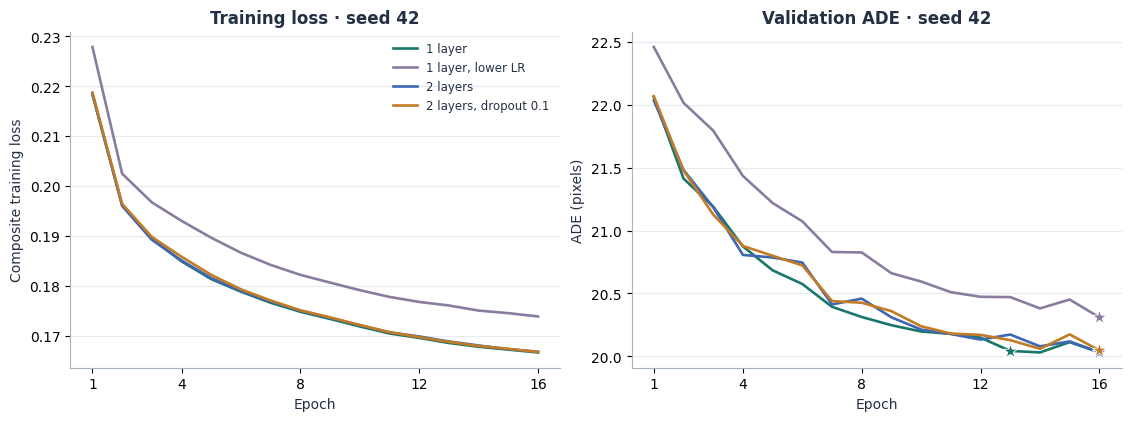

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1), layout="constrained")
short_labels = ["1 layer", "1 layer, lower LR", "2 layers", "2 layers, dropout 0.1"]
color_keys = ["baseline", "lr0005", "layers2_nodrop", "layers2_drop01"]
for name, label, key in zip(screen_names, short_labels, color_keys):
    trace = runs[name]["trace"]
    epochs = [row["epoch"] for row in trace]
    axes[0].plot(epochs, [row["loss"] for row in trace],
                 label=label, color=COLORS[key], linewidth=1.9)
    axes[1].plot(epochs, [row["validation"]["ade_px"] for row in trace],
                 color=COLORS[key], linewidth=1.9)
    selected = runs[name]["best_epoch"]
    axes[1].scatter(selected, trace[selected - 1]["validation"]["ade_px"],
                    marker="*", s=115, color=COLORS[key], edgecolors="white",
                    linewidth=0.6, zorder=5)
axes[0].set(title="Training loss · seed 42", xlabel="Epoch", ylabel="Composite training loss")
axes[1].set(title="Validation ADE · seed 42", xlabel="Epoch", ylabel="ADE (pixels)")
for ax in axes:
    ax.grid(axis="y", alpha=0.7)
    ax.set_xticks([1, 4, 8, 12, 16])
axes[0].legend(frameon=False, fontsize=8.5)
save_figure(fig, "01_seed42_learning_curves")

下面曲线的阴影表示每轮三个种子结果的“平均值 ± 一个样本标准差”。曲线画的是每一轮的值，不能直接把最后一个点当成前表中“各次最佳检查点”的平均值。

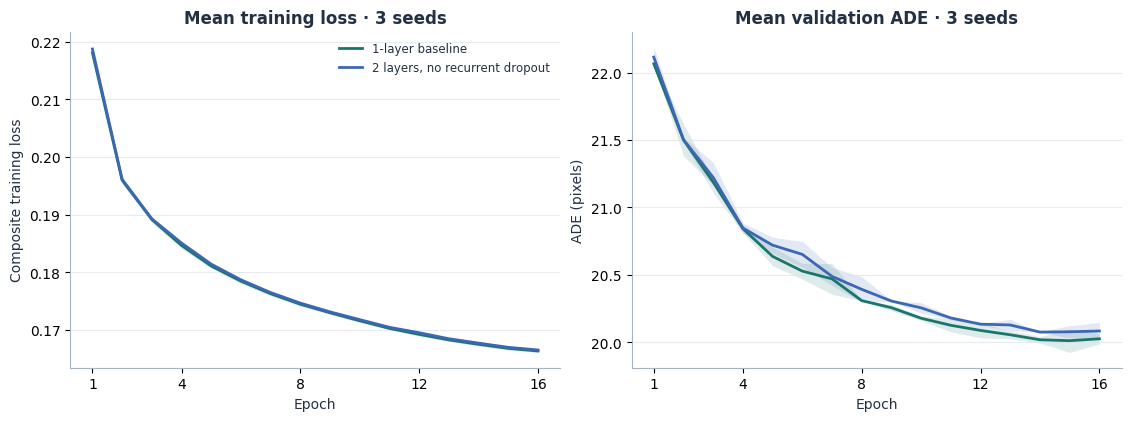

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.1), layout="constrained")
for variant, label in (
    ("baseline", "1-layer baseline"),
    ("layers2_nodrop", "2 layers, no recurrent dropout"),
):
    group = [runs[f"{variant}_seed{s}"] for s in (42, 43, 44)]
    epochs = np.arange(1, 17)
    loss = np.array([[row["loss"] for row in r["trace"]] for r in group])
    ade = np.array([
        [row["validation"]["ade_px"] for row in r["trace"]] for r in group
    ])
    for ax, values in zip(axes, (loss, ade)):
        mean = values.mean(axis=0)
        std = values.std(axis=0, ddof=1)
        ax.plot(epochs, mean, color=COLORS[variant], label=label, linewidth=2)
        ax.fill_between(epochs, mean - std, mean + std,
                        color=COLORS[variant], alpha=0.14, linewidth=0)
axes[0].set(title="Mean training loss · 3 seeds", xlabel="Epoch", ylabel="Composite training loss")
axes[1].set(title="Mean validation ADE · 3 seeds", xlabel="Epoch", ylabel="ADE (pixels)")
for ax in axes:
    ax.grid(axis="y", alpha=0.7)
    ax.set_xticks([1, 4, 8, 12, 16])
axes[0].legend(frameon=False, fontsize=8.5)
save_figure(fig, "02_repeated_learning_curves")

下面每个小点是一轮独立训练选出的最佳检查点指标，连线连接相同种子，黑色菱形和误差棒表示平均值 ± 样本标准差。这些图展示波动，不代表已完成显著性检验。

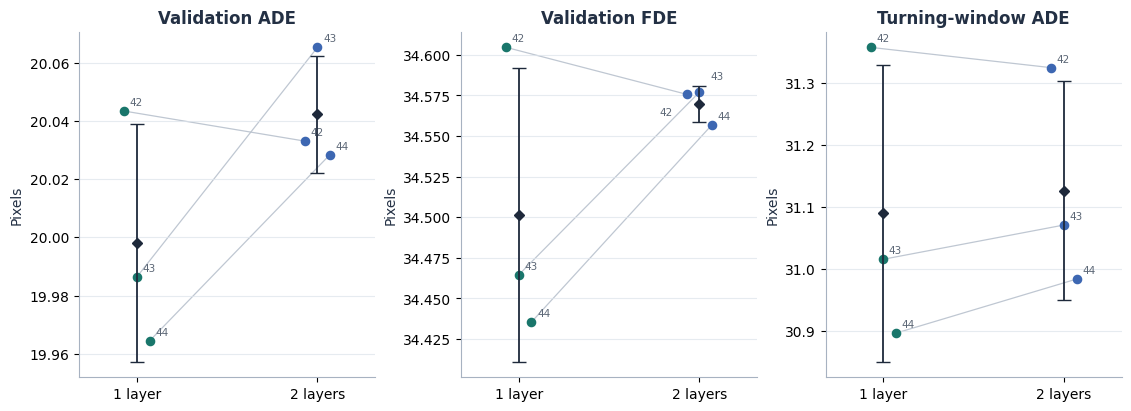

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11.2, 4.0), layout="constrained")
for ax, metric, title in zip(
    axes, ("ade_px", "fde_px", "turn_ade_px"),
    ("Validation ADE", "Validation FDE", "Turning-window ADE"),
):
    for seed, offset in zip((42, 43, 44), (-0.07, 0, 0.07)):
        values = [
            runs[f"{v}_seed{seed}"]["validation"][metric]
            for v in ("baseline", "layers2_nodrop")
        ]
        xs = np.array([0, 1]) + offset
        ax.plot(xs, values, color="#B8C1CD", linewidth=0.9, alpha=0.9, zorder=1)
        for x, value, variant in zip(xs, values, ("baseline", "layers2_nodrop")):
            ax.scatter(x, value, color=COLORS[variant], s=35, zorder=3)
            label_offset = (4, 4)
            alignment = "left"
            if metric == "fde_px" and variant == "layers2_nodrop" and seed == 42:
                label_offset, alignment = (-10, -15), "right"
            elif metric == "fde_px" and variant == "layers2_nodrop" and seed == 43:
                label_offset = (8, 9)
            ax.annotate(str(seed), (x, value), xytext=label_offset, ha=alignment,
                        textcoords="offset points", fontsize=7.5, color="#5B6675")
    for x, variant in enumerate(("baseline", "layers2_nodrop")):
        item = aggregate[variant][metric]
        ax.errorbar(x, item["mean"], yerr=item["sample_std"],
                    fmt="D", color="#1E293B", markersize=5.5,
                    capsize=5, linewidth=1.3, zorder=4)
    ax.set_xticks([0, 1], ["1 layer", "2 layers"])
    ax.set_xlim(-0.32, 1.32)
    ax.set(title=title, ylabel="Pixels")
    ax.grid(axis="y", alpha=0.7)
save_figure(fig, "03_best_checkpoint_metrics")

两套模型的共享模块参数都是 67,009 个。增加第二层 LSTM 后，编码器多了 33,280 个参数。日志里的计时包含训练和每轮验证，不包含预处理、模型创建和权重写盘；这不是预测一条轨迹所需的推理延迟。

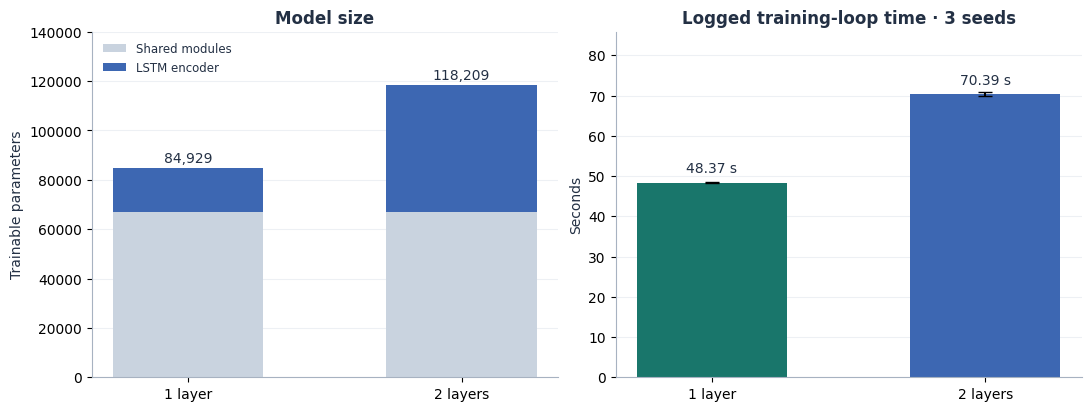

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), layout="constrained")
variants = ("baseline", "layers2_nodrop")
encoder_counts = [aggregate[v]["encoder_parameters"] for v in variants]
shared_counts = [
    aggregate[v]["parameters"] - aggregate[v]["encoder_parameters"]
    for v in variants
]
xs = np.arange(2)
axes[0].bar(xs, shared_counts, color="#C9D3DF", width=0.55, label="Shared modules")
axes[0].bar(xs, encoder_counts, bottom=shared_counts, color="#3D67B2",
            width=0.55, label="LSTM encoder")
for x, variant in enumerate(variants):
    total = aggregate[variant]["parameters"]
    axes[0].text(x, total + 2300, f"{total:,}", ha="center", fontsize=10)
axes[0].set_ylim(0, 140000)
axes[0].set(title="Model size", ylabel="Trainable parameters")
axes[0].ticklabel_format(axis="y", style="plain")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
times = [aggregate[v]["logged_loop_seconds"]["mean"] for v in variants]
stds = [aggregate[v]["logged_loop_seconds"]["sample_std"] for v in variants]
axes[1].bar(xs, times, yerr=stds, capsize=5, width=0.55,
            color=[COLORS[v] for v in variants])
for x, value in enumerate(times):
    axes[1].text(x, value + 2.5, f"{value:.2f} s", ha="center", fontsize=10)
axes[1].set_ylim(0, max(times) * 1.22)
axes[1].set(title="Logged training-loop time · 3 seeds", ylabel="Seconds")
for ax in axes:
    ax.set_xticks(xs, ["1 layer", "2 layers"])
    ax.grid(axis="y", alpha=0.5)
    ax.set_axisbelow(True)
save_figure(fig, "04_size_and_logged_time")

## 7. 最终选择与分析边界

**保留单层 LSTM，hidden size = 64，初始学习率 0.001，沿用共享位置/邻居分支和解码器。**小组三种编码器做统一配置比较时保留 seed42 基线；描述 LSTM 重复实验时汇总三个种子。

- 单层与两层各只有三次重复；较小学习率和 dropout 筛选各只有种子 42。
- 实验只涉及 GC 固定摄像机场景的一种划分，不能证明跨场景泛化能力。指标是像素，不能直接当作米单位成绩。
- 改变层数会同时改变参数量与初始化。已检查的共享工厂还会根据 recurrent_layers 改变参考 GRU 的层数，进而影响共享模块初始权重。因此，这里比较的是两套记录明确的配置，不能声称“仅增加一层、其余初始权重逐元素完全相同”的严格消融。
- 文件名中的 nodrop 只表示没有 LSTM 层间 dropout。共享融合模块的 0.05 dropout 始终存在。
- 8 次原始训练日志都记录 test_evaluated = false；已完成的最终评分另存于三个 test.json。共享 TEAM_GUIDE.md 说明此前开发已经多次查看过这个划分，最终小组报告需要说明这段开发历史，不能声称测试集在全部前期开发中从未被查看。
- 当前文件只分析已有日志，未包含其他组员的 GRU/Transformer、图像分支、碰撞率和真实预测轨迹图。上传包没有预测点或权重，所以这里没有凭空画预测路径。

上传的 LSTM 编码器是在提供的参考实现上做模块化接入。个人工作应按实际描述为：模型接入、实验配置、训练执行和分析；共享数据读取、训练循环与解码器属于团队代码。

## 8. 可复用结果与最终测试状态

下一段代码导出未四舍五入的统计汇总、选定配置和源文件哈希；原始训练日志保持不变。

最后一个单元格读取已完成的三个 test.json，全部来自此前选定的单层配置。每个检查点都评价完整的 45,454 个测试窗口，其中转弯窗口 8,309 个。代码核对数据指纹、各次训练的协议签名和样本数，导出 final_test_summary.json，并生成第 5 张图。

三个种子全部保留，不按测试分数挑种子或更换模型配置。“±”表示三个检查点在同一批测试窗口上的波动，不是三个独立数据集的误差范围。测试误差高于验证误差，转弯窗口依然更难；这些最终测试分数不再用于调参。

In [10]:
# Export values from the raw logs, without rounding the saved numbers.
per_run = {}
for name, r in runs.items():
    config = r["config"]
    per_run[name] = {
        "config": config,
        "effective_recurrent_dropout": (
            config["encoder_dropout"] if config["recurrent_layers"] > 1 else 0.0
        ),
        "best_epoch": r["best_epoch"],
        "validation": r["validation"],
        "selection_score": score(r),
        "parameters": r["parameters"],
        "encoder_parameters": r["encoder_parameters"],
        "logged_loop_seconds": r["seconds"],
        "test_evaluated": r["test_evaluated"],
    }
summary = {
    "scope": "LSTM validation analysis and frozen-configuration final test",
    "statistics": "mean and sample standard deviation; ddof=1",
    "repeated_seeds": [42, 43, 44],
    "per_run": per_run,
    "repeated_summary": aggregate,
    "paired_differences_two_minus_one": paired,
    "selection": {
        "variant": "baseline",
        "reference_seed_for_common_comparison": 42,
        "basis": "Lower mean validation selection score and lower model size",
        "status": "configuration_frozen",
    },
    "parameter_increase_two_layer_percent": parameter_increase,
    "logged_loop_time_increase_two_layer_percent": time_increase,
}
(ROOT / "analysis_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False) + "\n"
)
(ROOT / "selected_config.json").write_text(
    json.dumps(runs["baseline_seed42"]["config"], indent=2) + "\n"
)
source_manifest = {
    "original_training_logs": "User-provided lstm_results_for_analysis.zip",
    "shared_repository_reference": "Asuka-1883/9444_Proj",
    "shared_reference_commit": "290f214eb6938969fa77c9b70efed6355be73873",
    "scope_note": (
        "Only the two uploaded encoder files were provided as current source. "
        "Other shared-code descriptions refer to the inspected repository commit."
    ),
    "files_sha256": {},
}
for name in NAMES:
    path = ROOT / name / "result.json"
    source_manifest["files_sha256"][f"{name}/result.json"] = (
        hashlib.sha256(path.read_bytes()).hexdigest()
    )
for name in ("lstm_encoder.py", "motion_encoders.py"):
    path = ROOT.parents[1] / "gc_data_interface" / name
    source_manifest["files_sha256"][f"gc_data_interface/{name}"] = (
        hashlib.sha256(path.read_bytes()).hexdigest()
    )
(ROOT / "source_manifest.json").write_text(
    json.dumps(source_manifest, indent=2) + "\n"
)
print("Selected configuration: 1 layer, hidden size 64, initial LR 0.001.")
print("Saved analysis_summary.json, selected_config.json and source_manifest.json.")

Selected configuration: 1 layer, hidden size 64, initial LR 0.001.
Saved analysis_summary.json, selected_config.json and source_manifest.json.


| Seed | Test ADE (px) | Test FDE (px) | Turning ADE (px) | Turning FDE (px) |
| --- | --- | --- | --- | --- |
| 42 | 21.6442 | 37.4565 | 31.9975 | 61.2750 |
| 43 | 21.5481 | 37.1846 | 31.7055 | 60.2942 |
| 44 | 21.4690 | 37.0783 | 31.6431 | 60.4244 |

| Final test metric | Mean ± sample SD, 3 seeds |
| --- | --- |
| ade_px | 21.5538 ± 0.0877 |
| fde_px | 37.2398 ± 0.1951 |
| turn_ade_px | 31.7821 ± 0.1892 |
| turn_fde_px | 60.6646 ± 0.5326 |

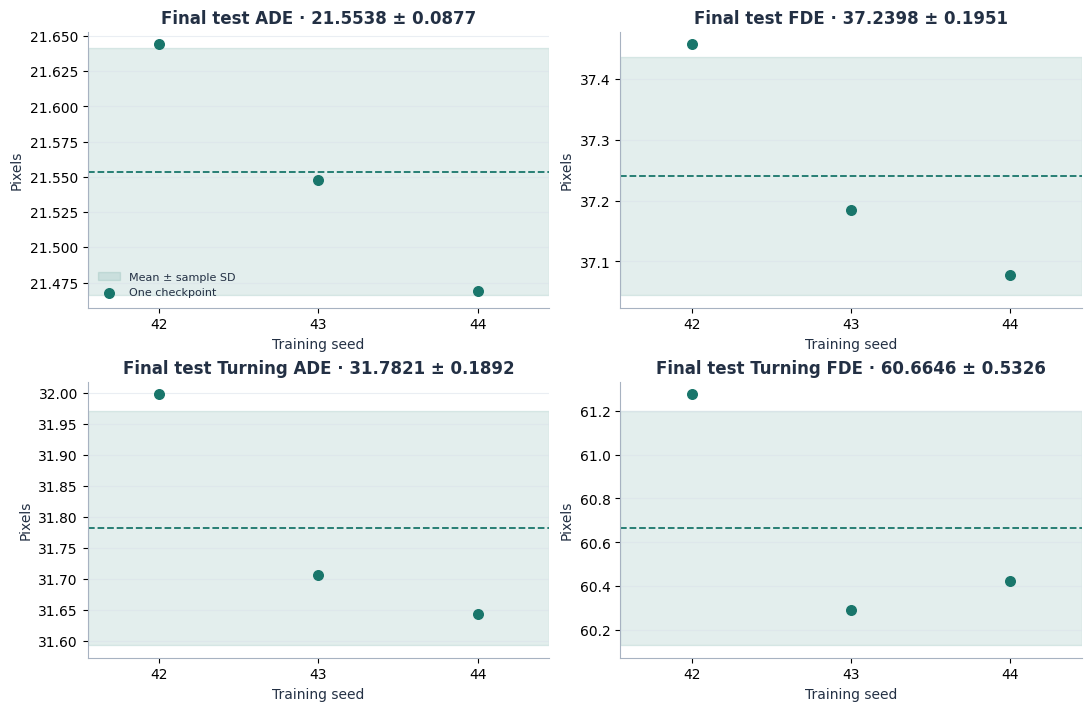

6 / 6 final-test checks passed.
Final test complete for the preselected configuration; all three seeds are retained.


In [11]:
# Score the already selected configuration; do not retune on these results.
test_paths = [ROOT / f"baseline_seed{s}" / "test.json" for s in (42, 43, 44)]
if not all(path.is_file() for path in test_paths):
    raise FileNotFoundError("This completed analysis requires all three baseline test.json files.")
test_runs = [json.loads(path.read_text()) for path in test_paths]
test_checks = {
    "three_expected_test_files": len(test_runs) == 3,
    "all_frozen_baseline_checkpoints": all(
        r["protocol_signature"] == runs[f"baseline_seed{s}"]["protocol_signature"]
        for s, r in zip((42, 43, 44), test_runs)
    ),
    "all_lstm_test_split": all(
        r["encoder"] == "lstm" and r["split"] == "test" for r in test_runs
    ),
    "complete_test_and_turning_windows": all(
        r["limit"] is None and r["metrics"]["samples"] == 45454
        and r["metrics"]["turn_samples"] == 8309 for r in test_runs
    ),
    "test_matches_training_data_protocol": all(
        r["data_fingerprint"] == hashlib.sha256(
            canonical(reference["protocol"]["data"]).encode()
        ).hexdigest() for r in test_runs
    ),
    "all_test_metrics_finite_nonnegative": all(
        math.isfinite(r["metrics"][k]) and r["metrics"][k] >= 0
        for r in test_runs for k in metrics
    ),
}
assert all(test_checks.values()), test_checks
test_aggregate = {
    metric: {
        "mean": statistics.mean(r["metrics"][metric] for r in test_runs),
        "sample_std": statistics.stdev(r["metrics"][metric] for r in test_runs),
    } for metric in metrics
}
test_summary = {
    "configuration": "Frozen one-layer LSTM, hidden size 64, initial LR 0.001",
    "configuration_selected_using": "Validation results before final test scoring",
    "seeds": [42, 43, 44],
    "unit": "pixels",
    "statistics": "mean and sample standard deviation; ddof=1",
    "test_samples_per_checkpoint": 45454,
    "turning_samples_per_checkpoint": 8309,
    "per_seed": {str(s): r for s, r in zip((42, 43, 44), test_runs)},
    "aggregate": test_aggregate,
    "checks": test_checks,
    "scope_note": (
        "Same test windows scored by three trained checkpoints; not three independent datasets. "
        "The shared guide discloses prior development on this split."
    ),
}
show_table(
    ["Seed", "Test ADE (px)", "Test FDE (px)", "Turning ADE (px)", "Turning FDE (px)"],
    [[s] + [f'{r["metrics"][k]:.4f}' for k in metrics]
     for s, r in zip((42, 43, 44), test_runs)],
)
show_table(
    ["Final test metric", "Mean ± sample SD, 3 seeds"],
    [[metric, f'{v["mean"]:.4f} ± {v["sample_std"]:.4f}']
     for metric, v in test_aggregate.items()],
)
fig, axes = plt.subplots(2, 2, figsize=(10.8, 7.0), layout="constrained")
for ax, metric, title in zip(
    axes.flat, metrics, ("ADE", "FDE", "Turning ADE", "Turning FDE"),
):
    item = test_aggregate[metric]
    mean, std = item["mean"], item["sample_std"]
    ax.axhspan(mean - std, mean + std, color=COLORS["baseline"], alpha=0.12,
               label="Mean ± sample SD")
    ax.axhline(mean, color=COLORS["baseline"], linewidth=1.3, linestyle="--")
    ax.scatter(range(3), [r["metrics"][metric] for r in test_runs],
               color=COLORS["baseline"], s=48, zorder=3, label="One checkpoint")
    ax.set_xticks(range(3), [42, 43, 44])
    ax.set_xlim(-0.45, 2.45)
    ax.set(title=f"Final test {title} · {mean:.4f} ± {std:.4f}",
           xlabel="Training seed", ylabel="Pixels")
    ax.grid(axis="y", alpha=0.6)
axes.flat[0].legend(frameon=False, fontsize=8, loc="lower left")
save_figure(fig, "05_final_test_results")

# Keep original training logs unchanged; final scoring has separate records.
summary["selection"]["status"] = "configuration_frozen_final_test_complete"
summary["final_test"] = test_summary
source_manifest["original_final_test_logs"] = "User-provided lstm_final_test_results.zip"
for path in test_paths:
    source_manifest["files_sha256"][path.relative_to(ROOT).as_posix()] = (
        hashlib.sha256(path.read_bytes()).hexdigest()
    )
for name, value in (
    ("final_test_summary.json", test_summary),
    ("analysis_summary.json", summary),
    ("source_manifest.json", source_manifest),
):
    (ROOT / name).write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
print(sum(test_checks.values()), "/", len(test_checks), "final-test checks passed.")
print("Final test complete for the preselected configuration; all three seeds are retained.")

## References

1. S. Hochreiter and J. Schmidhuber. Long Short-Term Memory. Neural Computation, 9(8), 1735–1780, 1997. [DOI](https://doi.org/10.1162/neco.1997.9.8.1735); [author PDF](https://people.idsia.ch/~juergen/lstm1997-2024head.pdf).
2. A. Alahi et al. Social LSTM: Human Trajectory Prediction in Crowded Spaces. CVPR, 2016. [Official paper page](https://openaccess.thecvf.com/content_cvpr_2016/html/Alahi_Social_LSTM_Human_CVPR_2016_paper.html).
3. S. Yi, H. Li and X. Wang. Understanding Pedestrian Behaviors from Stationary Crowd Groups. CVPR, 2015. [Official PDF](https://openaccess.thecvf.com/content_cvpr_2015/papers/Yi_Understanding_Pedestrian_Behaviors_2015_CVPR_paper.pdf).
4. PyTorch 2.15. LSTM API documentation. [Official documentation](https://docs.pytorch.org/docs/2.15/generated/torch.nn.LSTM.html).

References 1–2 explain the model family and social-interaction motivation. This implementation uses the supplied shared predictor and is not a reproduction of the Social LSTM architecture.